#installing required packages

In [1]:
!pip install -q transformers datasets accelerate
!pip install -q torch pandas numpy scikit-learn
!pip install -q matplotlib seaborn tqdm

#Data description

In [2]:
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("ParsiAI/snappfood-sentiment-analysis")

import pandas as pd

# Login using e.g. `huggingface-cli login` to access this dataset
splits = {'train': 'train.csv', 'validation': 'validation.csv', 'test': 'test.csv'}
df = pd.read_csv("hf://datasets/ParsiAI/snappfood-sentiment-analysis/" + splits["train"])

# Basic information
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate comments
print("\nDuplicate Comments:", df["comment"].duplicated().sum())

# Class distribution
print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nClass Distribution (%):")
print(df["label"].value_counts(normalize=True) * 100)

# Check label and label_id consistency
print("\nLabel Mapping:")
print(df.groupby("label")["label_id"].unique())

# Text length analysis
df["text_length"] = df["comment"].astype(str).apply(len)

print("\nText Length Statistics:")
print(df["text_length"].describe())

README.md:   0%|          | 0.00/447 [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 8.93MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv: reconstructing file:   0%|          |  0.00B / 1.42MB            

validation.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 1.54MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/52110 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/8337 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9033 [00:00<?, ? examples/s]

Dataset Shape: (52110, 3)

Columns: ['comment', 'label', 'label_id']

First 5 Rows:
                                             comment  label  label_id
0   غذا خیلی سرد بود در صورتیکه فاصله ما خیلی کم است    SAD       1.0
1     بهتره بتونیم ران یا سینه رو خودمون انتخاب کنیم  HAPPY       0.0
2  غذا بد بود حالم خیییییلی بده. دل دردو دل پیچه....    SAD       1.0
3  با سلام سابق بر این بسته بندی از کیفیت بهتری ب...    SAD       1.0
4                          سلام، خیلی ممنون و متشکرم  HAPPY       0.0

Data Types:
comment      object
label        object
label_id    float64
dtype: object

Missing Values:
comment     0
label       0
label_id    0
dtype: int64

Duplicate Comments: 0

Class Distribution:
label
HAPPY    26236
SAD      25874
Name: count, dtype: int64

Class Distribution (%):
label
HAPPY    50.347342
SAD      49.652658
Name: proportion, dtype: float64

Label Mapping:
label
HAPPY    [0.0]
SAD      [1.0]
Name: label_id, dtype: object

Text Length Statistics:
count    52110.000000


train dataset is clean and classes are are fairly well-balanced

#Forming Datasets

In [3]:
df_train = pd.read_csv("hf://datasets/ParsiAI/snappfood-sentiment-analysis/" + splits["train"])
df_test = pd.read_csv("hf://datasets/ParsiAI/snappfood-sentiment-analysis/" + splits["test"])
df_validation = pd.read_csv("hf://datasets/ParsiAI/snappfood-sentiment-analysis/" + splits["validation"])


#loading model and setting optimizer

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
from tqdm.auto import tqdm
from transformers import AutoTokenizer

MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 4
LEARNING_RATE = 2e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


class CommentDataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length=128):

        self.texts = dataframe["comment"].astype(str).tolist()
        self.labels = dataframe["label_id"].astype(int).tolist()

        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }


train_dataset = CommentDataset(df_train, tokenizer, MAX_LENGTH)
validation_dataset = CommentDataset(df_validation, tokenizer, MAX_LENGTH)
test_dataset = CommentDataset(df_test, tokenizer, MAX_LENGTH)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "HAPPY",
        1: "SAD"
    },
    label2id={
        "HAPPY": 0,
        "SAD": 1
    }
)

model.to(device)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

print("Model loaded successfully!")



Device: cuda
Train: 52110
Validation: 8337
Test: 9033


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

Model loaded successfully!


ParsBERT model loaded.
Model hyperparameters and optimizer are set.
In this cell, we define the key training hyperparameters: the maximum sequence length is set to 128, the batch size to 16, and the model is trained for 4 epochs with a learning rate of 2e-5.
 We use the AdamW optimizer for training. All experiments are conducted on Google Colab using an NVIDIA T4 GPU.

#Defining Learning Rate Schedualer

In [9]:
from transformers import get_linear_schedule_with_warmup

total_steps = len(train_loader) * EPOCHS
#num of updates

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),  # 10% of the total training steps are used for warmup
    num_training_steps=total_steps
)


Defines a learning rate scheduler with a 10% warmup phase followed by a linear decay throughout training.
download.svg

#Defining Evaluation Function

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def evaluate(model, dataloader):

    model.eval()

    predictions = []
    true_labels = []

    total_loss = 0

    with torch.no_grad():

        for batch in dataloader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)

            total_loss += outputs.loss.item()

            preds = torch.argmax(
                outputs.logits,
                dim=1
            )

            predictions.extend(preds.cpu().numpy())
            true_labels.extend(
                batch["labels"].cpu().numpy()
            )

    accuracy = accuracy_score(true_labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": total_loss / len(dataloader),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

An Evaluation function is defined to calculate the model loss, accuracy, macro precision, recall, and F1-score.

#ParsBERT Fine-Tuning and Training

In [11]:
import os

SAVE_PATH = "outputs/best_model"

os.makedirs(SAVE_PATH, exist_ok=True)

best_f1 = 0
patience = 2
patience_counter = 0

history = []

for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress_bar:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(**batch)

        loss = outputs.loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation
    val_metrics = evaluate(model, validation_loader)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Validation Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Validation Precision: {val_metrics['precision']:.4f}")
    print(f"Validation Recall: {val_metrics['recall']:.4f}")
    print(f"Validation Macro F1: {val_metrics['f1']:.4f}")

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_f1": val_metrics["f1"]
    })

    # Save best model
    if val_metrics["f1"] > best_f1:

        best_f1 = val_metrics["f1"]

        model.save_pretrained(SAVE_PATH)
        tokenizer.save_pretrained(SAVE_PATH)

        patience_counter = 0

        print("Best model saved!")

    else:

        patience_counter += 1

        print("No improvement.")

    # Early Stopping
    if patience_counter >= patience:

        print("Early stopping triggered.")
        break

print("\nTraining completed!")
print("Best Validation Macro F1:", best_f1)



Epoch 1/4:   0%|          | 0/3257 [00:00<?, ?it/s]


Epoch 1/4
Train Loss: 0.3618
Validation Loss: 0.3356
Validation Accuracy: 0.8756
Validation Precision: 0.8802
Validation Recall: 0.8760
Validation Macro F1: 0.8753


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!


Epoch 2/4:   0%|          | 0/3257 [00:00<?, ?it/s]


Epoch 2/4
Train Loss: 0.2783
Validation Loss: 0.3155
Validation Accuracy: 0.8732
Validation Precision: 0.8753
Validation Recall: 0.8734
Validation Macro F1: 0.8731
No improvement.


Epoch 3/4:   0%|          | 0/3257 [00:00<?, ?it/s]


Epoch 3/4
Train Loss: 0.2172
Validation Loss: 0.3824
Validation Accuracy: 0.8693
Validation Precision: 0.8751
Validation Recall: 0.8696
Validation Macro F1: 0.8688
No improvement.
Early stopping triggered.

Training completed!
Best Validation Macro F1: 0.8753012602110937


Trains ParsBERT for multiple epochs, evaluates it after each epoch, and saves the best-performing model based on validation Macro F1.
Applies early stopping if validation performance does not improve for two consecutive epochs.

After training for 3 epochs, we achieved an F1-score of 87.5%, which is quite close to the state of the art.

#Evalution on test set

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Final Test Results:
loss: 0.3407
accuracy: 0.8721
precision: 0.8757
recall: 0.8718
f1: 0.8718

Classification Report:
              precision    recall  f1-score   support

       HAPPY     0.9105    0.8235    0.8648      4486
         SAD     0.8408    0.9202    0.8787      4547

    accuracy                         0.8721      9033
   macro avg     0.8757    0.8718    0.8718      9033
weighted avg     0.8754    0.8721    0.8718      9033



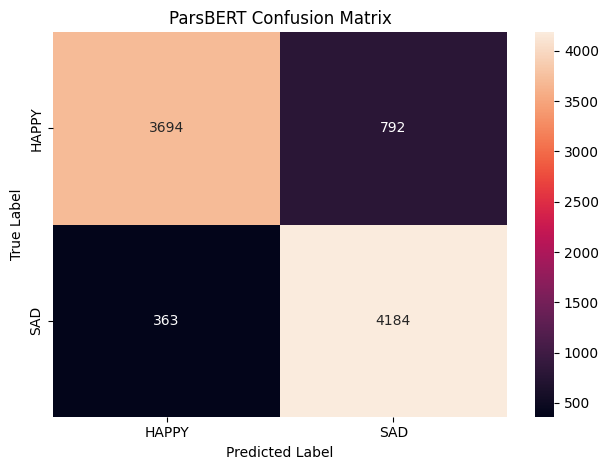

In [12]:

from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load best checkpoint
best_model = AutoModelForSequenceClassification.from_pretrained(
    SAVE_PATH
).to(device)

# Final test evaluation
test_metrics = evaluate(best_model, test_loader)

print("\nFinal Test Results:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

# Predictions for detailed evaluation
best_model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for batch in test_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = best_model(**batch)

        preds = torch.argmax(outputs.logits, dim=1)

        y_pred.extend(preds.cpu().numpy())
        y_true.extend(batch["labels"].cpu().numpy())

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["HAPPY", "SAD"],
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["HAPPY", "SAD"],
    yticklabels=["HAPPY", "SAD"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ParsBERT Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=300)
plt.show()


The model achieved an overall accuracy of 87.46% and a Macro F1-score of 87.40% on the test set.
It performed slightly better in classifying SAD comments (F1-score: 88.22%) than HAPPY comments (F1-score: 86.58%).
The model achieved higher recall for SAD (93.34%) but higher precision for HAPPY (92.35%).
Overall, the results indicate good classification performance, although the recall imbalance suggests room for improvement in detecting HAPPY comments.